In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
# Any import of metpy will activate the accessors
from metpy.units import units
import metpy.constants as constants
import geocat.viz as gv
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
from matplotlib.lines import Line2D
import cmocean

In [2]:
path_composite = '/glade/derecho/scratch/aiyyer/mse/composites/refV'
plotsdir = '/glade/u/home/athornton/plots/projections/'

In [3]:
# Variable selections
#variables = ['mse_vint', 'pv', 'v', 'u']
variables = ['mse_vint', 'cp', 'v', 'u', 'pv']

#varNames = ['mse_vint_prime', 'PV_prime', 'V_prime', 'U_prime']
varNames = ['mse_vint_prime', 'CP_prime', 'V_prime', 'U_prime', 'PV_prime']

itracks = [5, 3, 1]

lags = [-24, 0, 24]

level = 600

deltaLat = 15.
deltaLon = 30.

In [15]:
# retrieve data for each variable, track, and lag
def get_data(variab, itrack, varNam, lag):
    # print('level:', level)
    # print('itrack:', itrack)
    # print('variab:', variab)
    # print('varNam:', varNam)
    # print('lag:', lag)
    # v and u have different file names than other variables 
    if variab in ['v' ,'u', 'pv']:
        ds = xr.open_dataset(path_composite+str(level)+'/'+variab+ '_'+ str(level) +'_Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(itrack)+'.nc')
    else:
        ds = xr.open_dataset(path_composite+str(level)+'/'+variab+'_Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(itrack)+'.nc')
        #print(ds.units)
        
    # grab lon/lat reference points from ds
    lonRef = ds.Reflon.values
    latRef = ds.Reflat.values
    var = ds[varNam].sel(latitude=slice(30, -5),#(latRef+deltaLat, latRef-deltaLat), 
                                    longitude=slice(lonRef-deltaLon, lonRef+deltaLon)).metpy.quantify()
    print(var)
    if variab == 'cp':
        var = var.sel(Lag=lag)
        var = var*constants.density_water*constants.water_heat_vaporization
        var = var.metpy.convert_units('watts/(m**2)')
        # print(var.min())
        # print(var.max())
    else:
        var = var.sel(Lag=lag)
    # set lon/lat reference point as an attribute (accessible outside function)
    var.attrs['lonRef'] = lonRef
    var.attrs['latRef'] = latRef
    
    return var 

# plotting function
def plotting(ds, ds_v, ds_u, variab, ax, iplot):
    lon = ds['longitude'].values
    lat = ds['latitude'].values
    data = ds.values

    # set plotting window
    minlon = ds.attrs['lonRef'] - deltaLon
    maxlon = ds.attrs['lonRef'] + deltaLon
    minlat = -5. #ds.attrs['latRef'] - deltaLat
    maxlat = 30. #ds.attrs['latRef'] + deltaLat
    
    ax.set_extent([minlon, maxlon, minlat, maxlat], crs=ccrs.PlateCarree())
    # Using a dictionary makes it easy to reuse the same keyword arguments twice for the contours
    kwargs = dict(
                    transform=ccrs.PlateCarree(),  # ds projection
    )
    
    if variab == 'mse_vint':
        levels = np.arange(-9.e6, 9.e6, 3.e6)
        #print(data)
        m = ax.contour(lon, lat, data, levels=levels, colors='k', **kwargs, alpha=0.6)
    elif variab == 'cp':
        levels =  np.arange(-300, 300, 20)
        c = ax.contourf(lon, lat, data, levels=levels, cmap=cmocean.cm.tarn,extend='both', **kwargs)
    elif variab == 'pv':
        # print(np.max(data))
        # print(np.min(data))
        levels = np.arange(-1.e-7, 1.e-7, 4.e-8)
        c = ax.contourf(lon, lat, data, levels=[-1.e-7,-5.e-8], colors='none', extend='min',
        hatches=['..'], alpha=0.35, **kwargs)
        h = ax.contourf(lon, lat, data, levels=[5.e-8, 1.e-7], colors='none', extend='max',
        hatches=['xx'], alpha=0.35, **kwargs)
    else:
        q = ax.quiver(lon[::3],lat[::3],
              ds_u[::3,::3],ds_v[::3,::3],color='black',width=.002,
              scale=100.,headwidth=3.5,zorder=4, alpha=0.8)
    norm = plt.Normalize(vmin=-300, vmax=300) # for colorbar  
    sm = plt.cm.ScalarMappable(cmap=cmocean.cm.tarn, norm=norm) # for colorbar
    
    Rtitle = 'Lag = ' +str(lag)+ ' hr'
    Ltitle = 'Lat = ' + str(ds.latRef) + ' Lon = ' + str(ds.lonRef)
    # Use geocat.viz.util convenience function to set titles and labels
    gv.set_titles_and_labels(ax,
                         lefttitle=Ltitle,
                         righttitle=Rtitle,                         
                         lefttitlefontsize=15,
                         righttitlefontsize=15)  

    ax.scatter(ds.lonRef,ds.latRef,s=200,transform=ccrs.PlateCarree(),  marker='X', facecolor='maroon', edgecolor='white', linewidth=2, zorder=10)
    return sm


In [35]:
ds = xr.open_dataset('/glade/derecho/scratch/aiyyer/mse/composites/refV600/pv_850_Lag_Composite_RefV_600hPa_track_point_6.nc')

In [36]:
ds = ds.PV_prime.metpy.quantify()
print('units=',ds.metpy.units)
print('max=', ds.max().values)
print('min=',ds.min().values)

units= kelvin * meter ** 2 / kilogram / second
max= 3.7650522708483297e-07
min= -4.426819514020195e-07


<xarray.DataArray 'mse_vint_prime' (Lag: 25, latitude: 71, longitude: 121)> Size: 2MB
<Quantity([[[ -111505.07408859   -92390.75186335  -104183.8772782  ...
     348642.71201006   398801.18697113   412132.83206819]
  [ -113299.08959063   -82444.55038811   -89721.76653858 ...
     115218.01367921   134769.44511584   162267.0993608 ]
  [  -75835.05826541   -81687.53127805   -77505.66641218 ...
    -177646.03222249  -196343.79944169  -147840.69482132]
  ...
  [  110289.26606448   143528.39776393   151503.62705938 ...
     680273.05713933   676880.22037719   665797.94447058]
  [   35396.64497444    75936.1876756    113011.44198028 ...
     639817.06267413   622851.99274703   597327.39176348]
  [   35488.57218753    96671.33423943   147775.49628212 ...
     597914.19426904   569933.08475782   546537.24404631]]

 [[ -518789.60872289  -553604.72891143  -588612.77658857 ...
     247491.65844288   266327.66583489   309943.9085748 ]
  [ -501005.6679917   -497704.08248403  -506405.25624528 ...
  

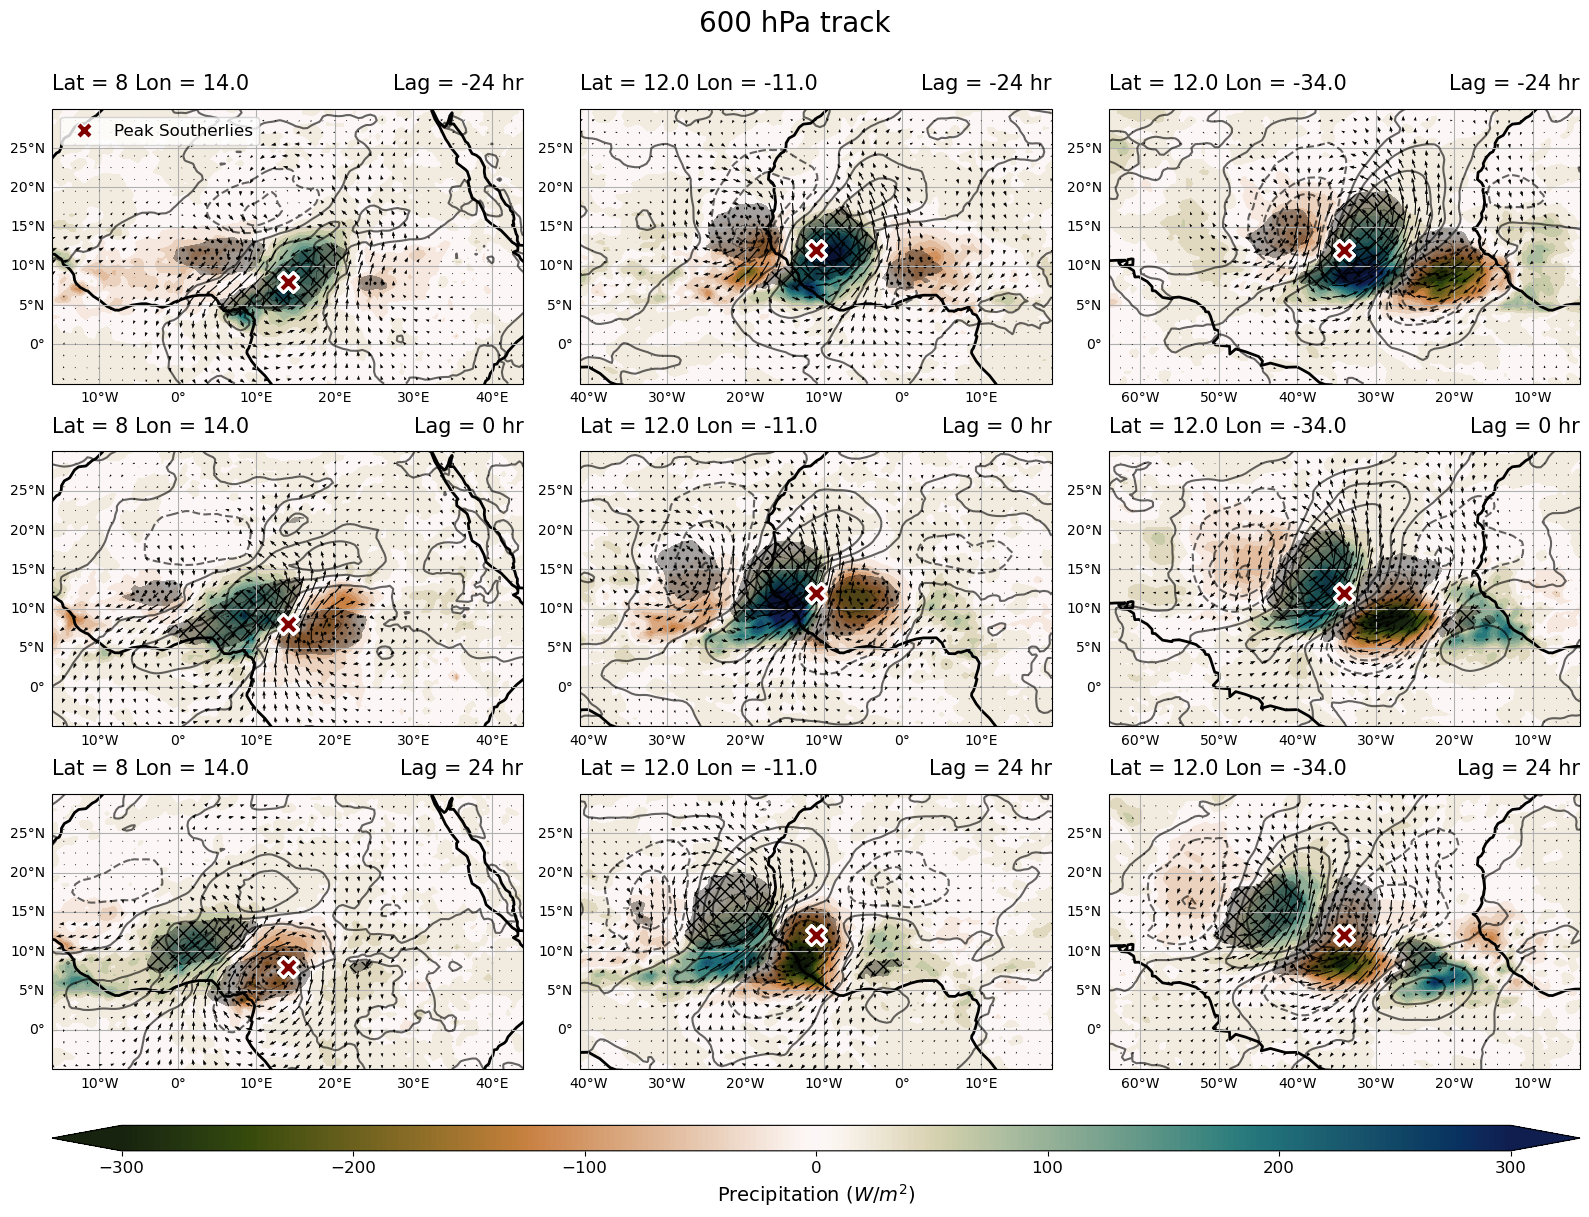

In [16]:
fig, ax = plt.subplots(3, 3, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(16,12))
cmap = 'BrBG'
plt.rcParams['savefig.dpi'] = 255
# Add coastlines or other features to all axes
continents = cartopy.feature.NaturalEarthFeature(
    name="coastline",
    category="physical",
    scale="110m",
    edgecolor="black",
    facecolor="none",
    linewidth=2
)
[axes.add_feature(continents) for axes in ax.flat]
# Add gridlines and tick labels to all subplots
for axes in ax.flat:
    gl = axes.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
    gl.top_labels = False  # Turn off labels on the top edge
    gl.right_labels = False  # Turn off labels on the right edge
    gl.xlabel_style = {'size': 10}  
    gl.ylabel_style = {'size': 10}                 
    
# Plotting: 3 rows (lags) x 3 columns (tracks)
for row, lag in enumerate(lags):  # Each row corresponds to a lag
    for col, itrack in enumerate(itracks):  # Each column corresponds to a track
        for variab, varNam in zip(variables, varNames):
            # Get data
            ds = get_data(variab, itrack, varNam, lag)
            ds_v = get_data(variables[2], itrack, varNames[2], lag)
            ds_u = get_data(variables[3], itrack, varNames[3], lag)
            # Plot on the correct axis
            current_ax = ax[row, col]
            sm = plotting(ds, ds_v, ds_u, variab, current_ax, row * 3 + col)

plt.subplots_adjust(top=0.9)  # increase space between plot and title
custom_legend = [Line2D([0], [0], marker='X', color='w',
                        markerfacecolor='maroon', markeredgecolor='white',
                        markersize=12, linewidth=0, label='Peak Southerlies')]
ax[0,0].legend(handles=custom_legend, loc='upper left', fontsize=12)
#plt.suptitle('Lags of MSE & Precipitation, ' +str(level)+ ' hPa track', weight='bold', fontsize=20)
plt.suptitle(str(level)+ ' hPa track', fontsize=20)
plt.tight_layout()

# Add the color bar
#cbar_ax = fig.add_axes([0.85, 0.15, 0.05, 0.7])
# Create a dummy image to generate the color bar
sm.set_array([])
# Add the color bar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.04, pad=0.05, extend='both', aspect=60)
cbar.set_label('Precipitation ($W/m^2$)', fontsize=14)
#cbar.set_label('PV (PVU)', fontsize=14)

cbar.ax.tick_params(labelsize=12) 
#plt.savefig(plotsdir+'lag_panel_track'+str(level)+'_mse_'+str(variables[1])+'.png')
#plt.savefig('lag_panel_track'+str(level)+'_mse_pv_cp.png')